# Módulo 1 — Punto 1.2: Calidad, Transformaciones de Intesnidad y Filtrado Espacial,

**Objetivo:** comprender la representación estadística de una imagen por medio de su histograma, aplicar cambios que impacten en el mismo, simular ruidos sobre la imagen y aplicar filtros.

**Cómo usar este notebook con otra foto/video:** no se toca nada acá. Se edita
`config.yaml` (ruta de la imagen o del video y la ROI) y se ejecuta todo de nuevo
(*Run All*).

Toda la lógica de cálculo está en `src/modulo1/calidad_intensidad_color.py`; este notebook
solo la llama y grafica.

## 0. Preparación del entorno

In [2]:
# --- Imports de la librería estándar ---
import sys                 # acceso a sys.path (dónde busca Python los módulos)
from pathlib import Path   # manejo de rutas independiente del sistema operativo

# --- Encontrar la raíz del repo ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros ---
import numpy as np                 # arrays (las imágenes son arrays)
import matplotlib.pyplot as plt    # gráficos
import matplotlib.patches as patches  # para dibujar el rectángulo de la ROI

# --- Imports propios ---
from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   # "cm" = alias corto
from src.modulo1 import calidad_filtrado as cf

# Leemos la configuración: un diccionario con todo lo del config.yaml
cfg = cargar_config(raiz / "config.yaml")

# Carpeta donde guardamos las figuras (se crea si no existe).
# parents=True crea carpetas intermedias; exist_ok=True no falla si ya existe.
carpeta_res = raiz / cfg["salida"]["carpeta_resultados"]
carpeta_res.mkdir(parents=True, exist_ok=True)

print("Raíz del repo:", raiz)
print("Resultados en:", carpeta_res)

Raíz del repo: c:\Users\Camila\Desktop\Guia_Imagenes\Guia-de-imagenes-biomedicas-G9-PSIB
Resultados en: c:\Users\Camila\Desktop\Guia_Imagenes\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo1


In [3]:
# Obtención de la imagen y ROI.

# Frame completo en RGB, como array (alto, ancho, 3) de uint8
img = cm.obtener_frame(cfg, raiz)

# Recorte de la ROI (copia independiente del original)
roi = cm.recortar_roi(img, cfg["roi"])

# 1.2.1 - Histograma y brullo/contraste

- `conv_grises` convierte la ROI de RGB (3 canales) a grises (1 canal) ponderando los distintos canales de acuerdo con la sensibilidad del ojo humano a estos colores.
- La funcion `histograma` recibe la ROI en escala de grises y devuelve un vector de 256 posiciones, donde la posición k contiene la cantidad de píxeles de la imagen cuya intensidad es k.

(137, 249) uint8


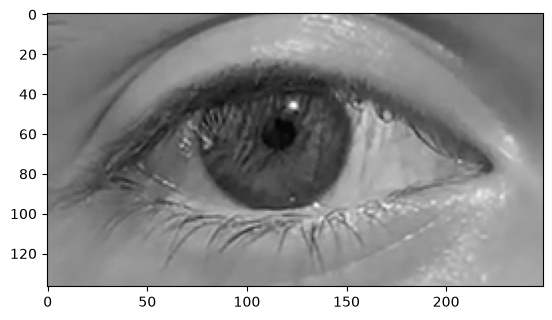

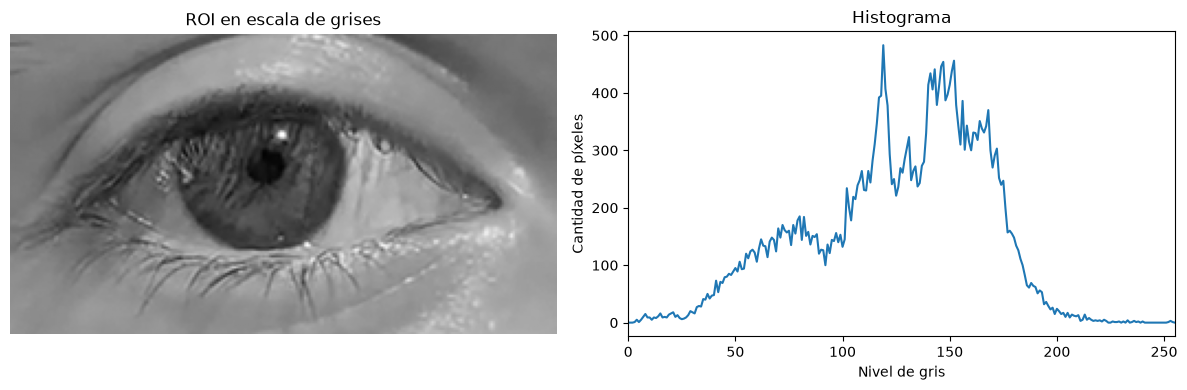

In [ ]:
roi_grises = cf.conv_grises(roi) #Llamo a la función conv_grises para convertir la ROI a escala de grises
print(roi_grises.shape, roi_grises.dtype) # Chequeo que la imagen sea 2D (que ya no figuren 3 canales)y de tipo uint8
plt.imshow(roi_grises, cmap='gray',vmin=0, vmax=255) 
plt.show() 

h = cf.histograma(roi_grises)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].imshow(roi_grises, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI en escala de grises")
ax[0].axis("off")

ax[1].plot(h)
ax[1].set_title("Histograma")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Frecuencia - Cantidad de píxeles")
ax[1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

Nótese que prácticamente no hay píxeles con intesnidades por encima de 200, y que la masa principal se concentra entre 50 y 190 aproximadamente. Esto indica que la imagen es de bajo contraste.

Tiene sentido observar un pico en 120 y zonas altas entre 140 y 170, correspondientes a zonas más claras como la piel y la esclerótica. Se observa entre 50 y 100 una cierta acumulación relacionada con el iris, la pupila y las pestañas, con valores de intensidad más bajos.